# Best fitted ellipse

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

The general formula of a ellipse is given by

$$x^2 + By^2 + Cxy + Dx + Ey + F = 0$$

That is, $$By^2 + Cxy + Dx + Ey + F = -x^2$$

We can see this problem as finding the function

$$f(x,y) = By^2 + Cxy + Dx + Ey + F$$
which minimizes the average distance to $-x^2$:

In [2]:
points = np.array([[0,2],[2,1],[1,-1],[-1,-2],[-3,1],[-3,-2]])

points_x = points[:,0]
points_y = points[:,1]
points_x2 = points_x**2
points_y2 = points_y**2
points_xy = points_x*points_y

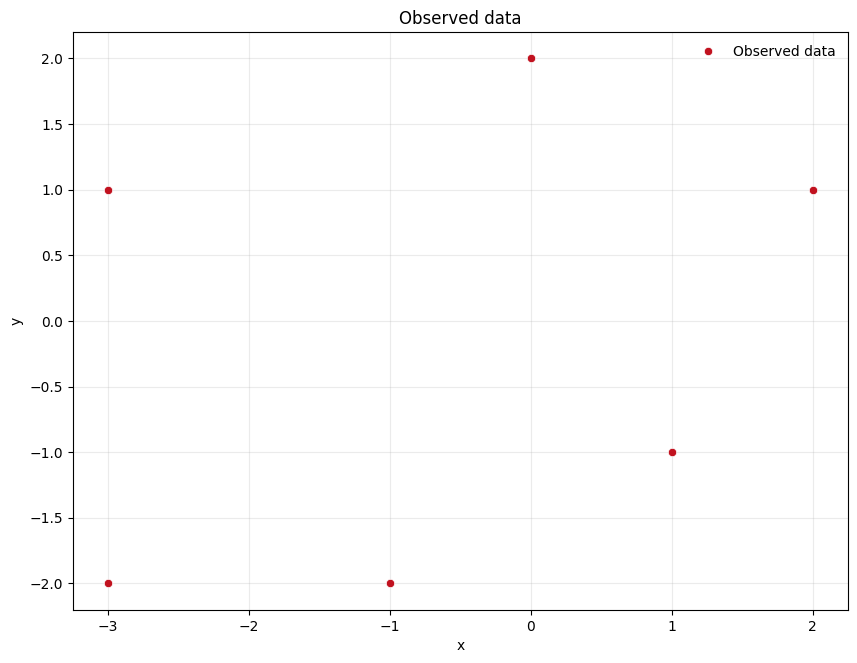

In [3]:
plt.figure(figsize=(10,7.5))
plt.plot(points_x, points_y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Observed data')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## Compute coefficients and calculate SSE

In [4]:
n = len(points)
Y = -points_x2
X = np.vstack([points_y2, points_xy, points_x, points_y, np.ones(len(points_x))]).T
p = X.shape[1]

In [5]:
# We compute the coeff.
B, C, D, E, F = np.linalg.lstsq(X, Y, rcond=None)[0]
params  = [B, C, D, E, F]

# Calculate the SSE
SSE = np.linalg.lstsq(X, Y, rcond=None)[1][0]

In [6]:
x_grid = np.linspace(-5, 3, 400)
y_grid = np.linspace(-3.5, 3.5, 400)
x_grid, y_grid = np.meshgrid(x_grid, y_grid)

# The fitted ellipse is the level set f_grid = 0
f_grid = x_grid**2 + B*y_grid**2 + C*x_grid*y_grid + D*x_grid + E*y_grid + F

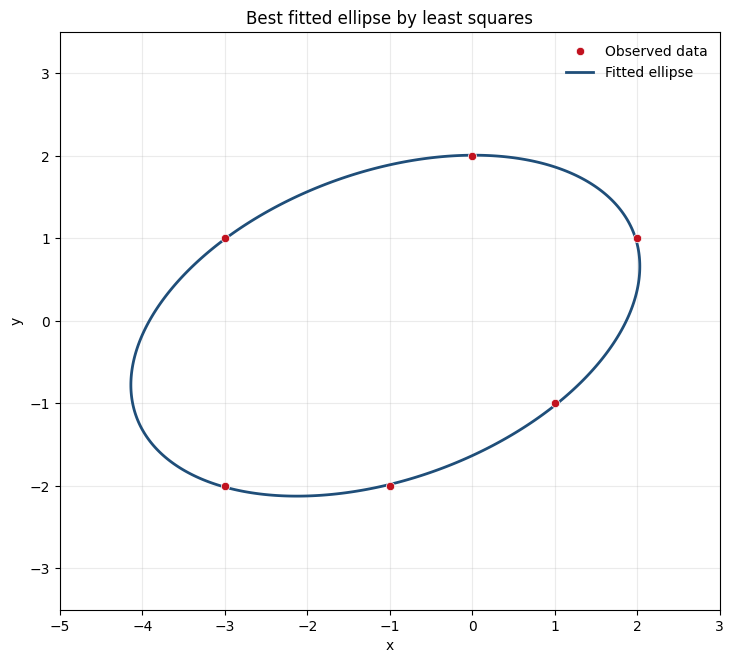

In [7]:
fig, ax = plt.subplots(figsize=(10,7.5))
CS = ax.contour(x_grid, y_grid, f_grid, [0], colors='#1f4e79', linewidths=2)
ax.plot(points_x, points_y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], color='#1f4e79', lw=2))
labels.append('Fitted ellipse')

ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Best fitted ellipse by least squares')
ax.legend(handles, labels, loc='best', frameon=False)
ax.grid(True, alpha=0.25)

## An heuristic for a "Confidence Region"
Remember that the points on the adjusted ellipse satisfied $\hat{f}(x,y)=0$.

So the interval is just given by
$$\pm t_{\alpha/2,n-p}\sqrt{\frac{\text{SSE}}{(n-p)}X_\text{grid}(X^TX)^{-1}X_\text{grid}^T},$$
which represent the level on which the conic surface should be cut.

In [8]:
# These are the points on the ellipse
points_ellipse = CS.allsegs[0][0]

ellipse_x = points_ellipse[:,0]
ellipse_y = points_ellipse[:,1]
ellipse_y2 = ellipse_y**2
ellipse_x2 = ellipse_x**2
ellipse_xy = ellipse_x*ellipse_y

ellipse_matrix = np.vstack([ellipse_y2, ellipse_xy, ellipse_x, ellipse_y, np.ones(len(ellipse_x))]).T

alpha = 0.05
aux_t = np.sqrt(SSE/(n-p)*(np.diag(ellipse_matrix @ np.linalg.inv(X.T @ X) @ ellipse_matrix.T)))
upp_contour = np.mean(t.ppf(1-alpha/2,n-p)*aux_t)
low_contour = np.mean(-t.ppf(1-alpha/2,n-p)*aux_t)

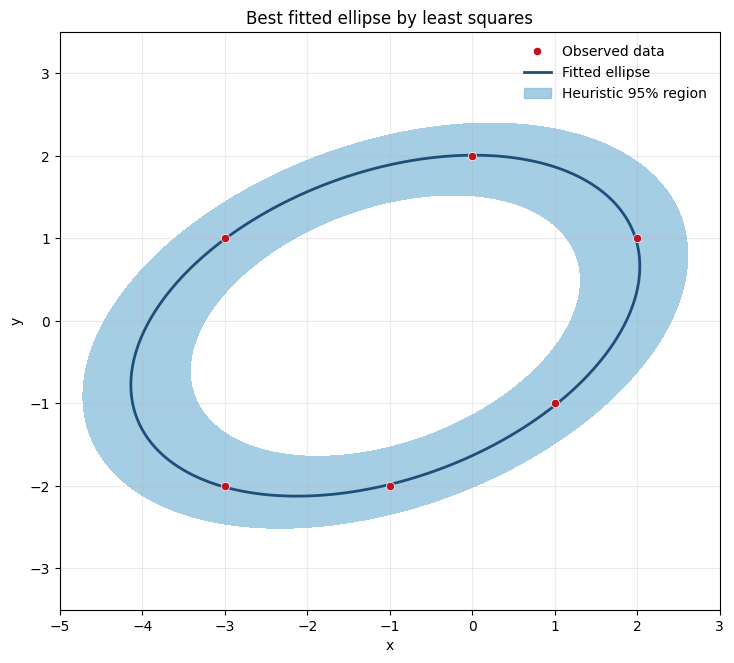

In [9]:
fig, ax = plt.subplots(figsize=(10,7.5))
region_label = f'Heuristic {(1 - alpha) * 100:.0f}% region'
ax.contourf(x_grid, y_grid, f_grid, [low_contour, upp_contour], colors=['#7fb8d8'], alpha=0.7)
ax.contour(x_grid, y_grid, f_grid, [0], colors='#1f4e79', linewidths=2)
ax.plot(points_x, points_y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

handles, labels = ax.get_legend_handles_labels()
handles += [Line2D([], [], color='#1f4e79', lw=2), Patch(color='#7fb8d8', alpha=0.7)]
labels += ['Fitted ellipse', region_label]

ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Best fitted ellipse by least squares')
ax.legend(handles, labels, loc='best', frameon=False)
ax.grid(True, alpha=0.25)